# Decision Tree Investigation

Muhammad Sarab Aftab

In this notebook I am training a decision tree on the shared training split and checking how it does on the dev split. I am leaving the test split alone for now.


## Loading the shared split

The preparation file removes duplicate URLs, makes the stratified split, and standardizes the numeric predictors inside a pipeline. I fit that pipeline on the training rows only, then transform the dev rows.


In [1]:
from sklearn.tree import DecisionTreeClassifier

import warnings

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

from dataset_preparation import prepare_datasets

data = prepare_datasets()
pipeline = data["pipeline"]

X_train = pipeline.fit_transform(data["X_train"])
X_dev = pipeline.transform(data["X_dev"])
y_train = data["y_train"]
y_dev = data["y_dev"]

print("Train rows:", X_train.shape[0])
print("Dev rows:", X_dev.shape[0])
print("Features:", X_train.shape[1])
print("Held-out test rows, not scored:", len(data["y_test"]))
print("Dev phishing rate:", round(float(y_dev.mean()), 4))


Train rows: 69138
Dev rows: 23046
Features: 22
Held-out test rows, not scored: 23047
Dev phishing rate: 0.144


The dev set is still about 14.4% phishing, so a model can look accurate while missing a lot of phishing URLs. Precision, recall, and F1 on the phishing class are reported along with accuracy and ROC AUC.


## Scoring function

The positive class is phishing (`label = 1`). ROC AUC uses the predicted phishing probability.


In [2]:
def phishing_scores(model, X, y):
    predictions = model.predict(X)
    phishing_probability = model.predict_proba(X)[:, 1]

    return {
        "accuracy": accuracy_score(y, predictions),
        "precision": precision_score(y, predictions, pos_label=1, zero_division=0),
        "recall": recall_score(y, predictions, pos_label=1, zero_division=0),
        "f1": f1_score(y, predictions, pos_label=1, zero_division=0),
        "roc_auc": roc_auc_score(y, phishing_probability),
    }


## Decision tree

These are my assigned settings: Gini splits, no depth limit, `min_samples_split=2`, `min_samples_leaf=1`, and every feature available at each split. There is no class weighting.


In [3]:
decision_tree = DecisionTreeClassifier(
    criterion="gini",
    splitter="best",
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features=None,
    class_weight=None,
    random_state=42,
)

decision_tree.fit(X_train, y_train)

print("Tree depth:", decision_tree.get_depth())
print("Leaves:", decision_tree.get_n_leaves())

scores = pd.DataFrame(
    {
        "train": phishing_scores(decision_tree, X_train, y_train),
        "dev": phishing_scores(decision_tree, X_dev, y_dev),
    }
).round(4)

scores


Tree depth: 27
Leaves: 2054


,train,dev
accuracy,0.9980,0.9717
precision,0.9986,0.9034
recall,0.9875,0.8993
f1,0.9930,0.9014
roc_auc,1.0000,0.9431


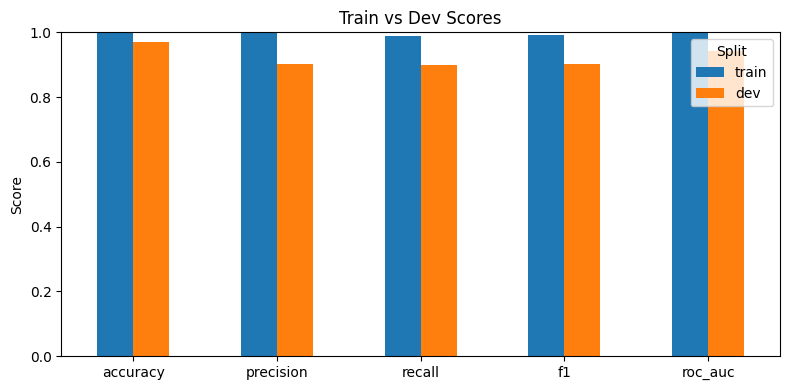

In [4]:
plt.figure(figsize=(8, 4))

scores.plot(kind="bar", ax=plt.gca())

plt.title("Train vs Dev Scores")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(title="Split")
plt.tight_layout()
plt.show()


## Conclusion

On the dev set, the decision tree gets about 0.972 accuracy, phishing recall of about 0.899, and an F1 of about 0.901. ROC AUC is about 0.943. The tree goes to depth 27 and has 2,054 leaves, and the training ROC AUC is 1.0, so it is fitting the training URLs very tightly.

It still catches more phishing URLs than logistic regression, so for recall and F1 this is the stronger of my two models.
